RESULTS USING RK3 AND SHOOTING METHOD
-------------------------------------
Step size h = 0.1
Shooting parameter s = 0.3320565334008507
Final value of f(eta) = 8.27922225854302
Final value of f'(eta) = 0.9999999999998738
Final value of f''(eta) = 8.220339926373556e-09
Residual = -1.262323578998803e-13


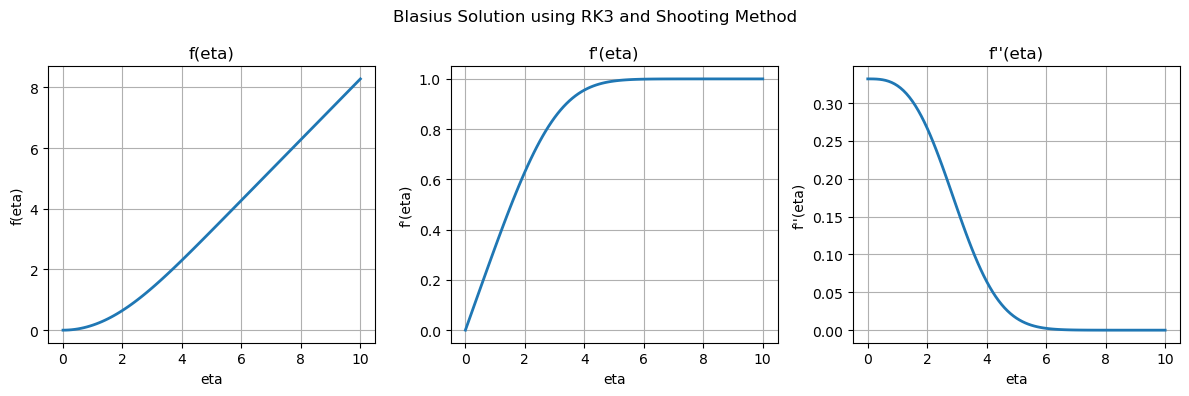

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Domain and step size
eta_inf = 10
h = 0.1


# First order system
def first_order(u1, u2, u3):

    du1 = u2
    du2 = u3
    du3 = -u1 * u3 / 2

    return np.array([du1, du2, du3])


# RK3 method
def RK3(s, h, eta_inf):

    N = round(eta_inf / h)
    h = eta_inf / N

    eta = np.linspace(0, eta_inf, N + 1)
    Y = np.zeros((N + 1, 3))

    # Initial conditions
    Y[0, 0] = 0
    Y[0, 1] = 0
    Y[0, 2] = s

    # Runge-Kutta third-order integration
    for i in range(N):

        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])

        K2 = h * first_order(
            Y[i, 0] + K1[0]/2,
            Y[i, 1] + K1[1]/2,
            Y[i, 2] + K1[2]/2
        )

        K3 = h * first_order(
            Y[i, 0] - K1[0] + 2*K2[0],
            Y[i, 1] - K1[1] + 2*K2[1],
            Y[i, 2] - K1[2] + 2*K2[2]
        )

        Y[i+1, 0] = Y[i, 0] + (K1[0] + 4*K2[0] + K3[0])/6
        Y[i+1, 1] = Y[i, 1] + (K1[1] + 4*K2[1] + K3[1])/6
        Y[i+1, 2] = Y[i, 2] + (K1[2] + 4*K2[2] + K3[2])/6

    # Residual
    error = Y[-1, 1] - 1

    return eta, Y, error


# Residual function for shooting method
def residual(s, h):

    eta, Y, err = RK3(s, h, eta_inf)

    return err


# Bisection method
def bisection(sl, su, eps, h):

    fl = residual(sl, h)
    fu = residual(su, h)

    if fl * fu > 0:
        raise ValueError("Initial interval does not contain a root")

    while (su - sl)/2 > eps:

        s = (sl + su)/2
        fm = residual(s, h)

        if fl * fm < 0:
            su = s
            fu = fm

        else:
            sl = s
            fl = fm

    return (sl + su)/2


# Shooting method
sl = 0.2
su = 0.5
eps = 1e-13

s = bisection(sl, su, eps, h)


# Calculate final solution using RK3
eta, Y, err = RK3(s, h, eta_inf)


# Display numerical results
print("RESULTS USING RK3 AND SHOOTING METHOD")
print("-------------------------------------")

print("Step size h =", h)
print("Shooting parameter s =", s)

print("Final value of f(eta) =", Y[-1, 0])
print("Final value of f'(eta) =", Y[-1, 1])
print("Final value of f''(eta) =", Y[-1, 2])

print("Residual =", err)


# Plot the solution
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

# Plot f(eta)
ax[0].plot(eta, Y[:, 0], linewidth=2)
ax[0].set_xlabel("eta")
ax[0].set_ylabel("f(eta)")
ax[0].set_title("f(eta)")

# Plot f'(eta)
ax[1].plot(eta, Y[:, 1], linewidth=2)
ax[1].set_xlabel("eta")
ax[1].set_ylabel("f'(eta)")
ax[1].set_title("f'(eta)")

# Plot f''(eta)
ax[2].plot(eta, Y[:, 2], linewidth=2)
ax[2].set_xlabel("eta")
ax[2].set_ylabel("f''(eta)")
ax[2].set_title("f''(eta)")

# Add grid to all plots
for a in ax:
    a.grid(True)

plt.suptitle("Blasius Solution using RK3 and Shooting Method")

plt.tight_layout()
plt.show()


RESULTS USING RK4 AND SHOOTING METHOD
-------------------------------------
Step size h = 0.1
Shooting parameter s = 0.3320573456105422
Final value of f(eta_inf) = 8.279212484488596
Final value of f'(eta_inf) = 0.9999999999999905
Final value of f''(eta_inf) = 8.458809105113045e-09
Residual = -9.547918011776346e-15


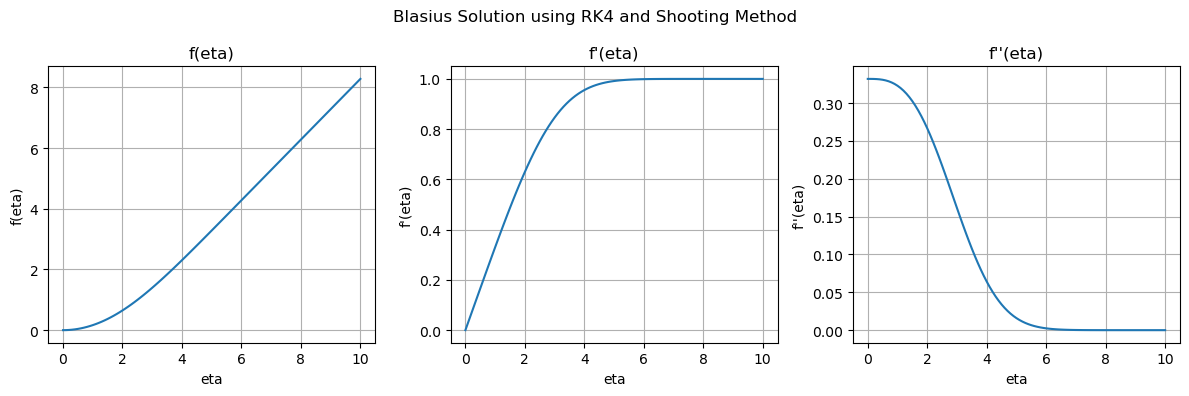

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Computational domain and parameters
eta_inf = 10
h = 0.1

sl = 0.2
su = 0.5
eps = 1e-13


# First order system
def first_order(u1, u2, u3):

    du1 = u2
    du2 = u3
    du3 = -u1 * u3 / 2

    return np.array([du1, du2, du3])


# RK4 method
def RK4(s, h, eta_inf):

    N = round(eta_inf / h)
    h = eta_inf / N

    eta = np.linspace(0, eta_inf, N + 1)
    Y = np.zeros((N + 1, 3))

    # Initial conditions
    Y[0, 0] = 0
    Y[0, 1] = 0
    Y[0, 2] = s

    for i in range(N):

        K1 = h * first_order(Y[i, 0], Y[i, 1], Y[i, 2])

        K2 = h * first_order(
            Y[i, 0] + K1[0]/2,
            Y[i, 1] + K1[1]/2,
            Y[i, 2] + K1[2]/2
        )

        K3 = h * first_order(
            Y[i, 0] + K2[0]/2,
            Y[i, 1] + K2[1]/2,
            Y[i, 2] + K2[2]/2
        )

        K4 = h * first_order(
            Y[i, 0] + K3[0],
            Y[i, 1] + K3[1],
            Y[i, 2] + K3[2]
        )

        Y[i+1, 0] = Y[i, 0] + (K1[0] + 2*K2[0] + 2*K3[0] + K4[0])/6
        Y[i+1, 1] = Y[i, 1] + (K1[1] + 2*K2[1] + 2*K3[1] + K4[1])/6
        Y[i+1, 2] = Y[i, 2] + (K1[2] + 2*K2[2] + 2*K3[2] + K4[2])/6

    # Residual calculation
    error = Y[-1, 1] - 1

    return eta, Y, error


# Residual function for shooting method
def residual_RK4(s, h):

    eta, Y, err = RK4(s, h, eta_inf)

    return err


# Bisection method
def bisection_RK4(sl, su, eps, h):

    fl = residual_RK4(sl, h)
    fu = residual_RK4(su, h)

    if fl * fu > 0:
        raise ValueError("Bisection interval does not contain a root")

    while (su - sl)/2 > eps:

        s = (sl + su)/2
        fm = residual_RK4(s, h)

        if fl * fm < 0:
            su = s
            fu = fm

        else:
            sl = s
            fl = fm

    return (sl + su)/2


# Shooting method using RK4
s_RK4 = bisection_RK4(sl, su, eps, h)

eta_RK4, Y_RK4, err_RK4 = RK4(s_RK4, h, eta_inf)


# Display numerical results
print("RESULTS USING RK4 AND SHOOTING METHOD")
print("-------------------------------------")

print("Step size h =", h)
print("Shooting parameter s =", s_RK4)

print("Final value of f(eta_inf) =", Y_RK4[-1, 0])
print("Final value of f'(eta_inf) =", Y_RK4[-1, 1])
print("Final value of f''(eta_inf) =", Y_RK4[-1, 2])

print("Residual =", err_RK4)


# Plot the solution
fig, ax = plt.subplots(1, 3, figsize=(12, 4))

# Plot f(eta)
ax[0].plot(eta_RK4, Y_RK4[:, 0])
ax[0].set_xlabel("eta")
ax[0].set_ylabel("f(eta)")
ax[0].set_title("f(eta)")

# Plot f'(eta)
ax[1].plot(eta_RK4, Y_RK4[:, 1])
ax[1].set_xlabel("eta")
ax[1].set_ylabel("f'(eta)")
ax[1].set_title("f'(eta)")

# Plot f''(eta)
ax[2].plot(eta_RK4, Y_RK4[:, 2])
ax[2].set_xlabel("eta")
ax[2].set_ylabel("f''(eta)")
ax[2].set_title("f''(eta)")

for a in ax:
    a.grid(True)

plt.suptitle("Blasius Solution using RK4 and Shooting Method")

plt.tight_layout()
plt.show()
